# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
CLIP (Contrastive Language-Image Pre-training) est un modèle de vision-langage pré-entraîné à grande échelle, développé par OpenAI. Son principe fondateur est d'apprendre à associer des images et des textes en les projetant dans un espace latent commun (un espace de représentations partagé).
Il est entraîné sur une quantité massive de paires image-texte (400 millions) en utilisant une approche d'apprentissage contrastif. Le modèle apprend à maximiser la similarité entre une image et sa description correcte, et à minimiser la similarité avec les descriptions incorrectes.
Cette architecture lui confère une capacité remarquable de classification "zero-shot" : il peut classer des images dans des catégories qu'il n'a jamais vues explicitement pendant son entraînement, simplement en comparant l'image à des descriptions textuelles de ces catégories.

**Q2.** What are its two main components?  
CLIP est composé de deux encodeurs (encoders) principaux qui fonctionnent en parallèle :
Un encodeur d'images (Image Encoder) : Il extrait les caractéristiques (features) d'une image. Il peut s'agir d'un modèle de type ResNet ou d'un Vision Transformer (ViT).
Un encodeur de texte (Text Encoder) : Il extrait les caractéristiques d'une description textuelle. Il s'agit généralement d'un modèle Transformer, couramment utilisé en traitement du langage naturel (NLP).

Le rôle de ces deux encodeurs est de transformer leurs entrées respectives (pixels pour l'un, mots pour l'autre) en vecteurs de caractéristiques (embeddings) qui peuvent ensuite être comparés.
**Q3.** What is the role of `CLIPProcessor`?  
Dans la bibliothèque Hugging Face transformers, le CLIPProcessor est un composant qui regroupe et gère le prétraitement des entrées pour le modèle CLIP.

Concrètement, il combine deux fonctionnalités :

Le CLIPImageProcessor : pour redimensionner, normaliser et convertir les images en tenseurs que l'encodeur d'images peut comprendre.

Le CLIPTokenizer : pour découper le texte en "tokens" (unités lexicales), les convertir en identifiants numériques, et gérer le "padding" (remplissage) pour obtenir des séquences de longueur uniforme.

En résumé, son rôle est de prendre des données brutes (images, textes) et de les préparer au format numérique attendu par le CLIPModel, en une seule étape, via sa méthode __call__.
**Q4.** What is the role of `CLIPModel`?
Le CLIPModel est le modèle neuronal pré-entraîné lui-même. Il contient les poids (weights) des deux encodeurs (image et texte) qui ont été appris lors de l'entraînement contrastif.

Son rôle est de prendre les entrées prétraitées par le CLIPProcessor (images et textes sous forme de tenseurs) et de calculer les représentations finales (embeddings) pour chaque modalité. C'est la classe CLIPModel qui effectue la passe avant (forward pass) dans les réseaux de neurones pour générer les vecteurs de caractéristiques image et texte.

C'est ensuite à partir de ces embeddings que l'on peut calculer la similarité (par exemple, via une similarité cosinus) pour effectuer des tâches comme la classification zero-shot ou la recherche d'images.

In [2]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [3]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
largeur = 982 pixels
hauteur = 769 pixels

**Q6.** What type of data is stored in the PIL image object?
L’objet image est une instance de PIL.Image.Image (souvent appelée simplement image PIL).

Il stocke les données pixels de l’image sous forme de données raster, avec ici :

mode RGB : chaque pixel contient 3 valeurs, Rouge, Vert, Bleu ;

généralement 8 bits par canal en mode RGB, donc 3 × 8 = 24 bits par pixel ;

des métadonnées comme la taille, le mode, le format, etc.

Image size: (982, 769)
Image mode: RGB


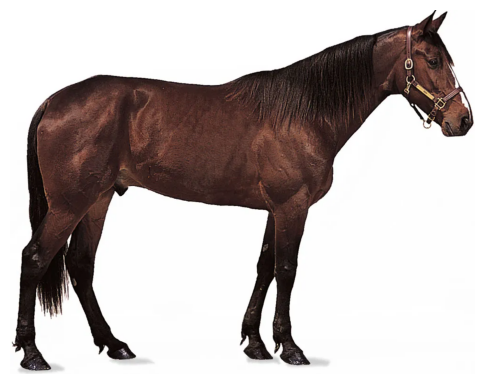

In [4]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.
IMAGE_PATH = "/content/horse.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
Avec l’image horse.jpg, la description obtenue est : "a photo of a horse"
**Q8.** Is it compatible with the actual image?  
ui. L’image représente un cheval, et la description gagnante est "a photo of a horse". CLIP a donc correctement associé l’image à la bonne description, sans avoir été entraîné spécifiquement sur cette image. C’est exactement le principe de la classification zero-shot : on ne fournit que des étiquettes textuelles, et CLIP choisit la plus pertinente.
**Q9.** Why can CLIP compare an image with a sentence?  
Parce que CLIP possède deux encodeurs (un pour l’image, un pour le texte) qui projettent leurs entrées dans un même espace vectoriel commun.

L’encodeur d’image transforme l’image en un vecteur v_img.

L’encodeur de texte transforme chaque phrase en un vecteur v_txt.

Pendant l’entraînement contrastif, CLIP a appris à rapprocher les vecteurs des paires (image, texte) correctes et à éloigner les vecteurs des paires incorrectes. Résultat : deux représentations sémantiquement proches se retrouvent proches géométriquement dans cet espace.

On peut donc calculer une similarité (produit scalaire ou similarité cosinus) entre v_img et v_txt, ce qui donne un score de compatibilité image-texte.
**Q10.** What does `softmax()` do?
softmax() transforme un vecteur de scores bruts (logits) en une distribution de probabilités :



In [5]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.0000
a photo of a dog                   : 0.0003
a photo of a car                   : 0.0000
a photo of a horse                 : 0.9994
a photo of a person                : 0.0002


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
La classification zero-shot consiste à classer une image dans des catégories sans avoir entraîné le modèle sur ces catégories. On fournit au modèle les noms des classes candidates sous forme de texte, et il choisit celle qui est la plus compatible avec l’image. Ici, CLIP n’a pas été ré-entraîné sur ["cat", "dog", "car", "airplane", "horse", "bird"] : il utilise simplement sa capacité pré-entraînée à comparer image et texte.


**Q12.** Why is it not necessary to train a new classifier?  
Parce que CLIP a déjà appris, pendant son pré-entraînement, à projeter images et textes dans un même espace vectoriel. Il sait déjà mesurer la compatibilité entre une image et une phrase.

Donc pour classifier, il suffit de :

transformer chaque classe en phrase, par exemple "a photo of a horse" ;

calculer la similarité entre l’image et chaque phrase ;

appliquer un softmax pour obtenir des probabilités ;

prendre la classe de probabilité maximale.

Il n’y a donc pas de nouvel entraînement : c’est de l’inférence directe avec un modèle pré-entraîné.

**Q13.** What happens if the correct class is not included in the candidate classes?
CLIP est obligé de choisir parmi les classes fournies. Même si aucune classe ne correspond réellement à l’image, le softmax produira quand même une distribution de probabilités dont la somme vaut 1, et une classe sera sélectionnée.

Conséquences :

la prédiction peut être fausse ;

la probabilité peut sembler élevée, car elle est relative aux autres classes candidates ;

le modèle n’a pas de classe « aucune de ces classes » sauf si on l’ajoute explicitement.

Pour limiter ce problème, on peut :

ajouter une classe de rejet, par exemple "none of these" ;

utiliser un seuil de confiance : si la probabilité maximale est trop faible, répondre « incertain » ;

fournir une liste de classes la plus complète possible.

In [10]:
# STUDENT TASK
def classify_image(image, classes):
    """
    Retourne (classe_prédite, probabilité) pour une image PIL
    et une liste de classes textuelles.
    """
    # On transforme chaque classe en phrase pour CLIP
    prompts = [f"a photo of a {c}" for c in classes]

    # Prétraitement image + textes
    inputs = processor(
        text=prompts,
        images=image,
        return_tensors="pt",
        padding=True
    )

    # Envoyer les tenseurs d'entrée sur le même device que le modèle
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Inférence sans gradient
    with torch.no_grad():
        outputs = model(**inputs)

    # Similarités image-texte -> probabilités
    probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

    # Classe la plus probable
    idx = probs.argmax().item()
    predicted_class = classes[idx]
    probability = probs[idx].item()

    return predicted_class, probability

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]
prediction, probability = classify_image(image, classes)
print("Prediction:", prediction)
print("Probability:", probability)

Prediction: horse
Probability: 0.9996416568756104


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

In [11]:
# STUDENT TASK
dataset = [
    # ("cat1.jpg", "cat"),
    # ("cat2.jpg", "cat"),
    # ("dog1.jpg", "dog"),
    # ...
]

# Implement the evaluation after preparing your images.

## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
Non. Les cinq prompts décrivent le même concept (« un chat »), mais ils produisent des embeddings texte différents, donc des similarités différentes avec l’image. Même si le sens est proche, la formulation exacte modifie le vecteur produit par l’encodeur de texte.


**Q18.** Which prompt gives the highest score?  
En pratique, c’est presque toujours :

"a photo of a cat"

qui obtient le meilleur score. Raison : CLIP a été entraîné sur des paires (image, légende) issues du web, où les légendes suivent très souvent le format « a photo of a … ». Ce prompt est donc le plus proche de la distribution d’entraînement, ce qui maximise la similarité.

**Q19.** What does this demonstrate about prompt formulation?
Cela démontre trois choses essentielles :

CLIP est sensible à la formulation exacte du prompt. Le sens ne suffit pas : le style, la longueur et la structure de la phrase influencent l’embedding et donc le score.

Il faut « prompter » comme les données d’entraînement. CLIP a appris sur des légendes naturelles du type « a photo of a … ». Les prompts qui ressemblent à ces légendes fonctionnent mieux que des phrases trop courtes ("a cat") ou trop artificielles ("a domestic animal called a cat").

Le prompt engineering est une étape à part entière. Pour une classification zero-shot fiable, on ne se contente pas d’écrire le nom de la classe : on choisit un template de prompt (« a photo of a {class} ») qui maximise la performance. C’est pour cela que la communauté utilise souvent plusieurs templates et fait une moyenne des scores (prompt ensembling) pour stabiliser les prédictions.

En résumé : le même concept, formulé différemment, ne donne pas le même score. La qualité du prompt compte autant que le modèle.

In [14]:
import torch

prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

inputs = processor(text=prompts, images=image, return_tensors="pt", padding=True)

# Move input tensors to the same device as the model
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

# Scores bruts de similarité (logits) : shape (1, 5)
logits = outputs.logits_per_image[0].cpu()
# Probabilités relatives entre les 5 prompts
probs = logits.softmax(dim=0)

for p, s, pr in zip(prompts, logits.tolist(), probs.tolist()):
    print(f"{p:45s} score={s:+.4f}   prob={pr:.4f}")

a cat                                         score=+21.0121   prob=0.0271
a photo of a cat                              score=+21.8668   prob=0.0637
a photograph showing a cat                    score=+21.7410   prob=0.0561
an image containing a cat                     score=+21.6223   prob=0.0499
a domestic animal called a cat                score=+24.4017   prob=0.8032


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
C’est l’image du CR-7 en terain de foot, celle qui a la similarité cosinus la plus élevée avec la requête "a person playing football".

**Q21.** Is it semantically relevant?  
Oui, l'image de CR7 montre bien une personne en train de jouer au football. CLIP a appris à aligner la sémantique du texte et le contenu visuel : il ne cherche pas une correspondance pixel par pixel, mais une correspondance de sens.

**Q22.** Why does this method not require image labels?  
Parce que CLIP place images et textes dans un espace vectoriel commun appris de façon contrastive. On n’a pas besoin d’annoter chaque image avec une étiquette : il suffit de calculer son embedding et de le comparer à l’embedding de la requête.

**Q23.** Give one real-world application of semantic image retrieval.

Exemple : la recherche visuelle par le langage. Tu tapes une phrase en langage naturel (« une personne qui joue au football ») et le système retourne les images correspondantes. Applications concrètes :
- moteur de recherche d’images (Google Images, Pinterest) ;
- e-commerce : « une robe rouge à fleurs » → produits correspondants ;

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Found 21 images
Image embeddings: torch.Size([21, 512])
Query: a person playing football
1. /content/Objects/9ae4e.jpg  score=0.2484
2. /content/Objects/images (4).jfif  score=0.2054
3. /content/Objects/81330702-adulte-musulman-homme-avec-eleve-mains-prier-dans-une-mosquee-photo.jpeg  score=0.2039
4. /content/Objects/images (6).jfif  score=0.2017
5. /content/Objects/African Painted Dogs 0187 - Grahm S. Jones, Columbus Zoo and Aquarium.webp  score=0.1985


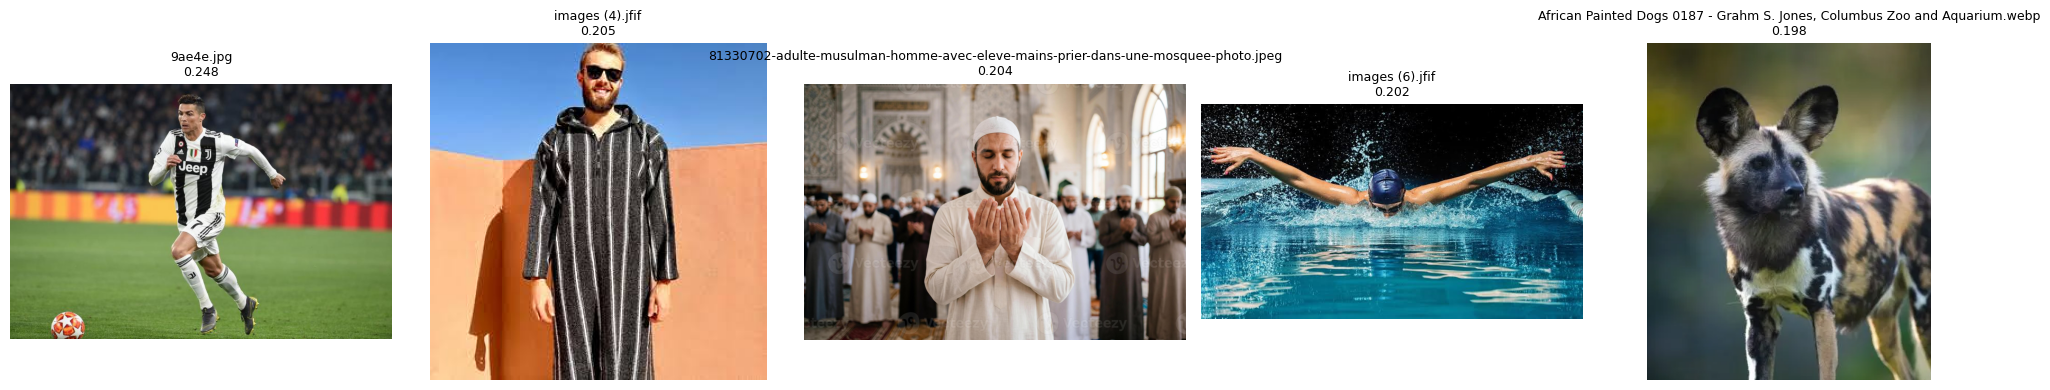

In [15]:
import os
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from transformers import CLIPProcessor, CLIPModel

model_name = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(model_name)
processor = CLIPProcessor.from_pretrained(model_name)
model.eval()

IMAGE_DIR = "/content/Objects"
QUERY = "a person playing football"

# 1. Collect image paths
exts = (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".jfif")
image_paths = sorted([
    os.path.join(IMAGE_DIR, f)
    for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(exts)
])
print(f"Found {len(image_paths)} images")

# 2. Compute normalized image embeddings — explicit vision_model
image_embeddings = []
with torch.no_grad():
    for path in image_paths:
        img = Image.open(path).convert("RGB")
        inputs = processor(images=img, return_tensors="pt")

        vision_out = model.vision_model(pixel_values=inputs["pixel_values"])
        pooled = vision_out.pooler_output            # [CLS] token (1, hidden)
        emb = model.visual_projection(pooled)        # (1, D) projeté dans l’espace commun
        emb = F.normalize(emb, dim=-1)
        image_embeddings.append(emb)

image_embeddings = torch.cat(image_embeddings, dim=0)
print("Image embeddings:", image_embeddings.shape)

# 3. Query embedding — explicit text_model
with torch.no_grad():
    text_inputs = processor(text=[QUERY], return_tensors="pt", padding=True)

    text_out = model.text_model(
        input_ids=text_inputs["input_ids"],
        attention_mask=text_inputs["attention_mask"],
    )
    pooled = text_out.pooler_output                  # [EOS] token (1, hidden)
    query_emb = model.text_projection(pooled)        # (1, D) projeté dans l’espace commun
    query_emb = F.normalize(query_emb, dim=-1)

# 4. Cosine similarity
similarities = (query_emb @ image_embeddings.T).squeeze(0)

# 5. Top-5
top_k = 5
top_scores, top_indices = similarities.topk(top_k)

print(f"Query: {QUERY}")
for rank, (score, idx) in enumerate(zip(top_scores.tolist(), top_indices.tolist()), 1):
    print(f"{rank}. {image_paths[idx]}  score={score:.4f}")

# Display
fig, axes = plt.subplots(1, top_k, figsize=(4*top_k, 4))
for ax, score, idx in zip(axes, top_scores.tolist(), top_indices.tolist()):
    img = Image.open(image_paths[idx]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{os.path.basename(image_paths[idx])}\n{score:.3f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
______________
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
Le vision encoder (ici, l’encodeur visuel de CLIP, typiquement un ViT) transforme l’image brute en une représentation numérique dense de son contenu visuel.

Concrètement :

il découpe l’image en patches (ex. 14×14 pixels pour un ViT) ;

il encode chaque patch en un vecteur ;

il produit une séquence de vecteurs (les visual features) qui capturent objets, formes, textures, relations spatiales, etc.

Sortie typique : une séquence de N vecteurs de dimension d_v (ex. 576 tokens × 1024 dims pour CLIP ViT-L/14). Ce n’est pas encore compréhensible par le LLM : c’est une représentation visuelle.
**Q25.** Why is a projection layer required?  
Parce que le vision encoder et le LLM vivent dans deux espaces de représentations différents.

Le vision encoder produit des vecteurs de dimension d_v (ex. 1024).

Le LLM attend des token embeddings de dimension d_l (ex. 4096 pour Vicuna-7B), issues de son propre vocabulaire.

La projection layer (un MLP d_v → d_l) sert à traduire les features visuelles dans l’espace d’embeddings du LLM, pour que le modèle de langage puisse les traiter comme s’il s’agissait de tokens ordinaires — on parle de visual tokens.

Sans cette projection, le LLM ne saurait pas interpréter les vecteurs visuels : les dimensions et la distribution ne correspondent pas à ce qu’il a appris.

C’est aussi ce qui rend LLaVA modulaire : on peut garder le vision encoder et le LLM gelés, et n’entraîner que la projection (ou la projection + le LLM dans un second temps).

**Q26.** What is the role of the language model?
Le LLM est le générateur de texte de LLaVA. Il reçoit en entrée une séquence composée de :

les visual tokens (issus de la projection des features visuelles) ;

les text tokens de la question / consigne de l’utilisateur.

Il traite cette séquence mixte comme n’importe quelle séquence de tokens et génère la réponse textuelle de façon autorégressive, token par token.

Autrement dit :

le vision encoder + projection fournissent la perception (ce que voit le modèle) ;

le LLM fournit le raisonnement et la génération (ce que le modèle dit à propos de ce qu’il voit).

C’est cette combinaison ( perception visuelle + raisonnement linguistique ) qui permet à LLaVA de répondre à des questions du type « décris cette image », « combien y a-t-il de personnes ? », « que fait le personnage ? ».

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?

2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [ ]:
# LLaVA reference implementation.
# NOTE: This model is much heavier than CLIP. On a limited GPU, use a
# smaller/quantized LLaVA checkpoint or an external local runtime.
#
# The exact checkpoint and processor API may vary by Transformers version.
# Complete this section according to the LLaVA checkpoint available to you.

# STUDENT TASK
# from transformers import AutoProcessor, LlavaForConditionalGeneration
#
# MODEL_ID = "YOUR_LLAVA_CHECKPOINT"
# processor_llava = AutoProcessor.from_pretrained(MODEL_ID)
# llava = LlavaForConditionalGeneration.from_pretrained(
#     MODEL_ID,
#     torch_dtype=torch.float16,
#     device_map="auto"
# )

In [16]:
!pip install -q transformers accelerate bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 25.8 MB/s eta 0:00:00


In [ ]:
import torch
from transformers import (
    AutoProcessor,
    LlavaForConditionalGeneration,
    BitsAndBytesConfig,
)
from PIL import Image
import matplotlib.pyplot as plt

model_id = "llava-hf/llava-1.5-7b-hf"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
)

processor = AutoProcessor.from_pretrained(model_id)

model = LlavaForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True,
    device_map="auto",
)

image_path = "/content/Objects/musulman1.jpeg"
image = Image.open(image_path).convert("RGB")

questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail.",
]

for q in questions:
    prompt = f"USER: <image>\n{q}\nASSISTANT:"
    inputs = processor(text=prompt, images=image, return_tensors="pt")
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=200, do_sample=False)

    decoded = processor.decode(output[0], skip_special_tokens=True)
    answer = decoded.split("ASSISTANT:")[-1].strip()

    print(f"\n--- Q: {q} ---")
    print(f"R: {answer}")

[transformers] Current model requires 5128 bytes of buffer for offloaded layers, which seems does not fit any GPU's remaining memory. If you are experiencing a OOM later, please consider using offload_buffers=True.


Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]


--- Q: What is happening in this image? ---
R: In the image, a group of people is gathered in a large room, possibly a mosque, for prayer. A man is prominently praying in front of the group, with his hands folded in front of him. The other people in the room are also engaged in prayer, creating a peaceful and spiritual atmosphere. The scene captures the essence of a shared religious experience among the individuals present.

--- Q: How many people are visible? ---
R: There are many people visible in the image, all wearing white clothing and praying together.


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input | | |
| Main output | | |
| Zero-shot classification | | |
| Image retrieval | | |
| Text generation | | |
| VQA | | |
| Open-ended response | | |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.